CELL 1 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


CELL 2 — Upload the Dataset

In [4]:
from google.colab import files

uploaded = files.upload()

Saving FAOSTAT_data_en_9-24-2026.csv to FAOSTAT_data_en_9-24-2026.csv


CELL 3 — Load the Dataset

In [5]:
df = pd.read_csv("FAOSTAT_data_en_9-24-2026.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


CELL 4 — Check Dataset Size

In [6]:
print("Dataset shape:", df.shape)

Dataset shape: (12417, 15)


CELL 5 — View Column Names

In [7]:
print(df.columns.tolist())

['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (CPC)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description', 'Note']


CELL 6 — Preview the Dataset

In [8]:
df.head()

,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1961,1961,An,12300.0,E,Estimated value,NaN
1,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1962,1962,An,11700.0,E,Estimated value,NaN
2,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1963,1963,An,11000.0,E,Estimated value,NaN
3,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1964,1964,An,11108.0,A,Official value,NaN
4,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1965,1965,An,8891.0,A,Official value,NaN


CELL 6 — Inspect Dataset

In [9]:
print("FIRST 5 ROWS")
display(df.head())

print("\nDATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

FIRST 5 ROWS


,Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (CPC),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1961,1961,An,12300.0,E,Estimated value,NaN
1,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1962,1962,An,11700.0,E,Estimated value,NaN
2,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1963,1963,An,11000.0,E,Estimated value,NaN
3,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1964,1964,An,11108.0,A,Official value,NaN
4,QCL,Crops and livestock products,288,Ghana,5111,Stocks,02132,Asses,1965,1965,An,8891.0,A,Official value,NaN



DATA TYPES
Domain Code          object
Domain               object
Area Code (M49)       int64
Area                 object
Element Code          int64
Element              object
Item Code (CPC)      object
Item                 object
Year Code             int64
Year                  int64
Unit                 object
Value               float64
Flag                 object
Flag Description     object
Note                 object
dtype: object

MISSING VALUES
Domain Code             0
Domain                  0
Area Code (M49)         0
Area                    0
Element Code            0
Element                 0
Item Code (CPC)         0
Item                    0
Year Code               0
Year                    0
Unit                    0
Value                 431
Flag                    0
Flag Description        0
Note                11987
dtype: int64

DUPLICATE ROWS
0


NEXT CELL — Explore Relevant Variables

In [10]:
selected_crops = ["Maize (corn)", "Rice", "Cassava, fresh", "Yams"]

print("AVAILABLE ELEMENTS")
print(df["Element"].value_counts())

print("\nSELECTED CROPS")
print(df[df["Item"].isin(selected_crops)]["Item"].value_counts())

print("\nYEAR RANGE")
print(df["Year"].min(), "-", df["Year"].max())

print("\nUNITS FOR SELECTED CROPS")
print(
    df[df["Item"].isin(selected_crops)]
    .groupby(["Element", "Unit"])
    .size()
)

AVAILABLE ELEMENTS
Element
Production                       4882
Area harvested                   2705
Yield                            2590
Producing Animals/Slaughtered    1024
Yield/Carcass Weight              640
Stocks                            448
Laying                             64
Milk Animals                       64
Name: count, dtype: int64

SELECTED CROPS
Item
Cassava, fresh    192
Maize (corn)      192
Rice              192
Yams              192
Name: count, dtype: int64

YEAR RANGE
1961 - 2024

UNITS FOR SELECTED CROPS
Element         Unit 
Area harvested  ha       256
Production      t        256
Yield           kg/ha    256
dtype: int64


NEXT CELL — Create Our Project Dataset & Check Quality

In [11]:
# Keep only the crops and measurements needed
elements = ["Production", "Area harvested", "Yield"]

crop_df = df[
    df["Item"].isin(selected_crops) &
    df["Element"].isin(elements)
].copy()

# Check the filtered dataset
print("PROJECT DATASET SHAPE")
print(crop_df.shape)

print("\nRECORDS BY CROP AND ELEMENT")
print(pd.crosstab(crop_df["Item"], crop_df["Element"]))

print("\nMISSING VALUES")
print(crop_df[["Item", "Element", "Year", "Unit", "Value"]].isnull().sum())

print("\nYEAR COVERAGE BY CROP")
print(crop_df.groupby("Item")["Year"].agg(["min", "max", "nunique"]))

PROJECT DATASET SHAPE
(768, 15)

RECORDS BY CROP AND ELEMENT
Element         Area harvested  Production  Yield
Item                                             
Cassava, fresh              64          64     64
Maize (corn)                64          64     64
Rice                        64          64     64
Yams                        64          64     64

MISSING VALUES
Item       0
Element    0
Year       0
Unit       0
Value      0
dtype: int64

YEAR COVERAGE BY CROP
                 min   max  nunique
Item                               
Cassava, fresh  1961  2024       64
Maize (corn)    1961  2024       64
Rice            1961  2024       64
Yams            1961  2024       64


NEXT CELL — Check FAOSTAT Data Flags

In [12]:
print("FLAG DESCRIPTIONS")
print(crop_df["Flag Description"].value_counts())

print("\nFLAGS BY CROP")
print(pd.crosstab(crop_df["Item"], crop_df["Flag Description"]))

print("\nFLAGS BY ELEMENT")
print(pd.crosstab(crop_df["Element"], crop_df["Flag Description"]))

FLAG DESCRIPTIONS
Flag Description
Official value                         625
Estimated value                        116
Value imputed by a receiving agency     14
Value from external organization        13
Name: count, dtype: int64

FLAGS BY CROP
Flag Description  Estimated value  Official value  \
Item                                                
Cassava, fresh                 87              99   
Maize (corn)                    7             175   
Rice                           10             178   
Yams                           12             173   

Flag Description  Value from external organization  \
Item                                                 
Cassava, fresh                                   0   
Maize (corn)                                     9   
Rice                                             4   
Yams                                             0   

Flag Description  Value imputed by a receiving agency  
Item                                                

CELL 8 — Summary Statistics

In [13]:
summary = (
    crop_df.groupby(["Item", "Element"])["Value"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

display(summary)

count        mean      median        min  \
Item           Element                                                    
Cassava, fresh Area harvested     64   541538.02   533250.00   140000.0   
               Production         64  8098102.35  5837050.00  1050000.0   
               Yield              64    12138.28    10946.95     6666.7   
Maize (corn)   Area harvested     64   648220.61   633050.00   173277.0   
               Production         64  1086722.05   934736.50   172000.0   
               Yield              64     1456.84     1456.75      430.0   
Rice           Area harvested     64   128916.19   105125.00    27518.0   
               Production         64   299695.60   154150.00    30400.0   
               Yield              64     1789.03     1662.80      590.2   
Yams           Area harvested     64   254655.91   205550.00    87000.0   
               Production         64  3343874.93  2200245.00   535000.0   
               Yield              64    10928.22    11388.65     5067.2   

                                       max         std  
Item           Element                                  
Cassava, fresh Area harvested   1079366.00   317193.42  
               Production      27917780.52  7741999.62  
               Yield              25865.00     5396.54  
Maize (corn)   Area harvested   1368623.00   321243.67  
               Production       3794000.00   906072.89  
               Yield               2772.10      505.73  
Rice           Area harvested    472900.00    98581.36  
               Production       1721200.00   369926.14  
               Yield               3735.00      850.04  
Yams           Area harvested    580707.00   144025.22  
               Production      10702900.69  3055898.69  
               Yield              18849.00     4579.03

NEXT CELL — Historical Trend Visualization

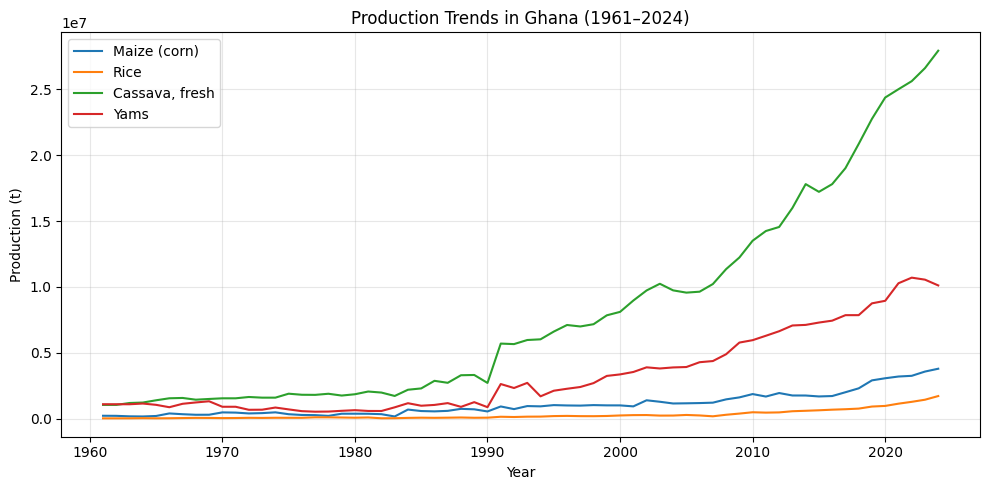

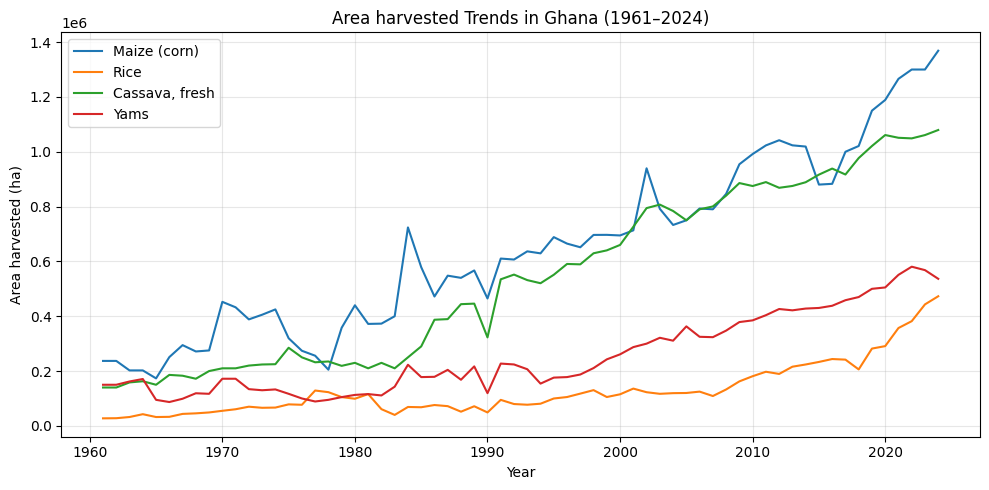

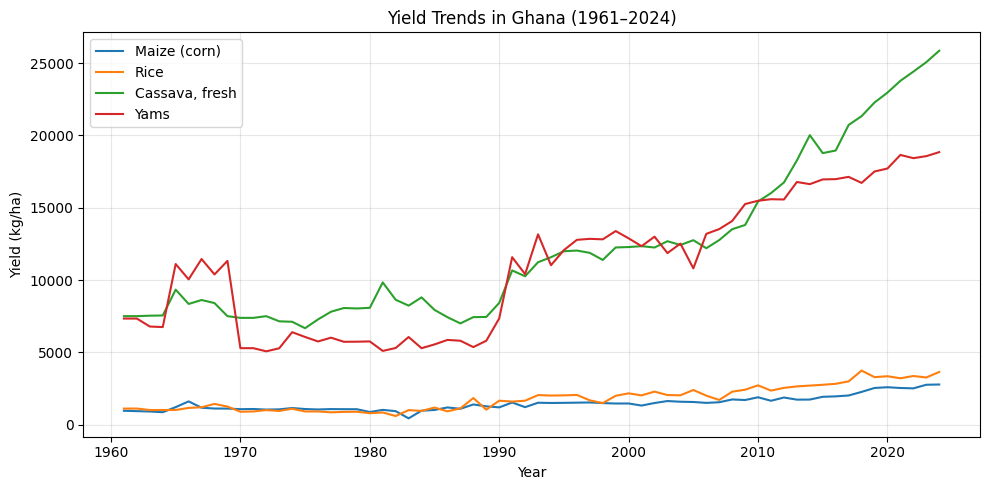

In [14]:
elements = ["Production", "Area harvested", "Yield"]

for element in elements:
    plot_data = crop_df[crop_df["Element"] == element]

    plt.figure(figsize=(10, 5))

    for crop in selected_crops:
        crop_data = plot_data[plot_data["Item"] == crop]
        plt.plot(crop_data["Year"], crop_data["Value"], label=crop)

    unit = plot_data["Unit"].iloc[0]

    plt.title(f"{element} Trends in Ghana (1961–2024)")
    plt.xlabel("Year")
    plt.ylabel(f"{element} ({unit})")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

NEXT CELL — Calculate Long-Term Change

In [15]:
change = (
    crop_df[crop_df["Year"].isin([1961, 2024])]
    .pivot_table(
        index=["Item", "Element"],
        columns="Year",
        values="Value"
    )
)

change["Absolute Change"] = change[2024] - change[1961]

change["Percent Change"] = (
    (change[2024] - change[1961]) / change[1961] * 100
)

display(change.round(2))

Year                                1961         2024  Absolute Change  \
Item           Element                                                   
Cassava, fresh Area harvested   140000.0   1079366.00        939366.00   
               Production      1050000.0  27917780.52      26867780.52   
               Yield              7500.0     25865.00         18365.00   
Maize (corn)   Area harvested   237000.0   1368623.00       1131623.00   
               Production       226000.0   3794000.00       3568000.00   
               Yield               953.6      2772.10          1818.50   
Rice           Area harvested    27518.0    472900.00        445382.00   
               Production        30400.0   1721200.00       1690800.00   
               Yield              1104.7      3639.70          2535.00   
Yams           Area harvested   150000.0    536529.00        386529.00   
               Production      1100000.0  10113013.74       9013013.74   
               Yield              7333.3     18849.00         11515.70   

Year                           Percent Change  
Item           Element                         
Cassava, fresh Area harvested          670.98  
               Production             2558.84  
               Yield                   244.87  
Maize (corn)   Area harvested          477.48  
               Production             1578.76  
               Yield                   190.70  
Rice           Area harvested         1618.51  
               Production             5561.84  
               Yield                   229.47  
Yams           Area harvested          257.69  
               Production              819.36  
               Yield                   157.03

In [16]:
change = (
    crop_df[crop_df["Year"].isin([1961, 2024])]
    .pivot_table(
        index=["Item", "Element"],
        columns="Year",
        values="Value"
    )
)

change["Absolute Change"] = change[2024] - change[1961]

change["Percent Change"] = (
    (change[2024] - change[1961]) / change[1961] * 100
)

display(change.round(2))

Year                                1961         2024  Absolute Change  \
Item           Element                                                   
Cassava, fresh Area harvested   140000.0   1079366.00        939366.00   
               Production      1050000.0  27917780.52      26867780.52   
               Yield              7500.0     25865.00         18365.00   
Maize (corn)   Area harvested   237000.0   1368623.00       1131623.00   
               Production       226000.0   3794000.00       3568000.00   
               Yield               953.6      2772.10          1818.50   
Rice           Area harvested    27518.0    472900.00        445382.00   
               Production        30400.0   1721200.00       1690800.00   
               Yield              1104.7      3639.70          2535.00   
Yams           Area harvested   150000.0    536529.00        386529.00   
               Production      1100000.0  10113013.74       9013013.74   
               Yield              7333.3     18849.00         11515.70   

Year                           Percent Change  
Item           Element                         
Cassava, fresh Area harvested          670.98  
               Production             2558.84  
               Yield                   244.87  
Maize (corn)   Area harvested          477.48  
               Production             1578.76  
               Yield                   190.70  
Rice           Area harvested         1618.51  
               Production             5561.84  
               Yield                   229.47  
Yams           Area harvested          257.69  
               Production              819.36  
               Yield                   157.03

CELL 11 — Estimate Linear Trends

In [17]:
from scipy.stats import linregress

trend_results = []

for crop in selected_crops:
    for element in elements:
        data = crop_df[
            (crop_df["Item"] == crop) &
            (crop_df["Element"] == element)
        ]

        result = linregress(data["Year"], data["Value"])

        trend_results.append({
            "Crop": crop,
            "Element": element,
            "Annual Trend": result.slope,
            "R²": result.rvalue ** 2,
            "P-value": result.pvalue
        })

trend_df = pd.DataFrame(trend_results)

display(trend_df.round(4))

,Crop,Element,Annual Trend,R²,P-value
0,Maize (corn),Production,43243.7080,0.7896,0.0
1,Maize (corn),Area harvested,16504.2929,0.9150,0.0
2,Maize (corn),Yield,23.1905,0.7289,0.0
3,Rice,Production,15900.7426,0.6405,0.0
4,Rice,Area harvested,4372.6395,0.6820,0.0
5,Rice,Yield,41.3522,0.8204,0.0
6,"Cassava, fresh",Production,379964.5223,0.8350,0.0
7,"Cassava, fresh",Area harvested,16640.4489,0.9541,0.0
8,"Cassava, fresh",Yield,257.5303,0.7895,0.0
9,Yams,Production,146932.1659,0.8014,0.0


CELL 12 — Show Exact P-values

In [18]:
for _, row in trend_df.iterrows():
    print(
        f"{row['Crop']} | {row['Element']} | "
        f"p = {row['P-value']:.3e}"
    )

Maize (corn) | Production | p = 1.162e-22
Maize (corn) | Area harvested | p = 6.751e-35
Maize (corn) | Yield | p = 3.129e-19
Rice | Production | p = 2.108e-15
Rice | Area harvested | p = 4.545e-17
Rice | Yield | p = 8.485e-25
Cassava, fresh | Production | p = 6.067e-26
Cassava, fresh | Area harvested | p = 3.389e-43
Cassava, fresh | Yield | p = 1.191e-22
Yams | Production | p = 1.929e-23
Yams | Area harvested | p = 1.597e-25
Yams | Yield | p = 1.843e-18


CELL 13 — Save Project Results

In [20]:
crop_df.to_csv("ghana_crop_data_clean.csv", index=False)
summary.to_csv("summary_statistics.csv")
change.to_csv("long_term_change.csv")
trend_df.to_csv("linear_trend_results.csv", index=False)

print("Project files saved successfully.")

Project files saved successfully.


In [21]:
import os

print("CSV files currently in Colab:")
print([f for f in os.listdir() if f.lower().endswith(".csv")])

CSV files currently in Colab:
['FAOSTAT_data_en_9-24-2026 .csv', 'long_term_change.csv', 'ghana_crop_data_clean.csv', 'summary_statistics.csv', 'FAOSTAT_data_en_9-24-2026.csv', 'linear_trend_results.csv']


Cell — Recreate the Clean Crop Dataset

In [22]:
selected_crops = [
    "Maize (corn)",
    "Rice",
    "Cassava, fresh",
    "Yams"
]

elements = [
    "Production",
    "Area harvested",
    "Yield"
]

df = pd.read_csv("FAOSTAT_data_en_9-24-2026.csv")

crop_df = df[
    df["Item"].isin(selected_crops) &
    df["Element"].isin(elements)
].copy()

crop_df.to_csv("ghana_crop_data_clean.csv", index=False)

print("Clean crop dataset recreated successfully.")
print("Shape:", crop_df.shape)

Clean crop dataset recreated successfully.
Shape: (768, 15)


In [23]:
import pandas as pd

selected_crops = [
    "Maize (corn)",
    "Rice",
    "Cassava, fresh",
    "Yams"
]

elements = [
    "Production",
    "Area harvested",
    "Yield"
]

df = pd.read_csv("FAOSTAT_data_en_9-24-2026.csv")

crop_df = df[
    df["Item"].isin(selected_crops) &
    df["Element"].isin(elements)
].copy()

crop_df.to_csv("ghana_crop_data_clean.csv", index=False)

print("Clean crop dataset recreated successfully.")
print("Shape:", crop_df.shape)

Clean crop dataset recreated successfully.
Shape: (768, 15)
